# 04 · TIIM (polar rays) → triplane (TPV), step by step

**`TRIPLANE_LIFTERS["tiim"]` → `lifting.triplane.PolarRayTriplaneLifter`**  ·  Saha et al., *Translating Images into Maps* (ICRA 2022) · `tiimnet.py`

> A transformer turns every image column into a polar ray of depth cells; every voxel reads the ray at its (column, range) AND the image at its (column, row) for height - then collapse along Z, Y and X.

This notebook shows, cell by cell, how the **TIIM (polar rays)** lifting technique produces a
**tri-perspective view** (three orthogonal feature planes `xy` = BEV, `xz`, `yz`) instead of a single
bird's-eye-view map, *without changing a line of the existing BEV lifter* - the triplane module wraps it
(composition) and only adds what is needed to keep the height axis.

| § | what you will see |
|---|---|
| 1 | the idea, the animated step-by-step GIF and a detailed Mermaid diagram |
| 2 | every animation step as a still image |
| 3 | the shared toy scene (4 cameras, vehicles, pedestrians) |
| 4 | building the triplane lifter from the registry |
| 5 | **inside the lifter**: every intermediate tensor, with exact checks |
| 6 | the triplane contract, verified |
| 7 | end-to-end training on 3D semantic occupancy |
| 8 | the negative control: does it really use the cameras? |
| 9 | how to use it in your own code, recap, cheat sheet, exercises |

## 1. The idea

![TIIM (polar rays) triplane lifting animation](../../assets/triplane/tiim.gif)


TIIM treats lifting as **sequence-to-sequence translation**: an image *column* (a vertical strip of `h` pixels) is
encoded by a transformer, and `D` learned depth queries decode it into a **polar ray** - `D` features, one per range
bin, along that column's viewing direction. Stacking all columns gives a polar map `(C, D, W)` per camera.

The polar ray has **consumed the row axis** - it knows *how far* things are along the column, not *how high*. The BEV
lifter is fine with that (it samples the rays at one height). For a 3D triplane that is not enough, so
`PolarRayTriplaneLifter.polar_to_voxels` gives every voxel **two** features:

1. **range feature** - the polar ray sampled at the voxel's column `u` and depth `d` (TIIM's learned depth reasoning);
2. **elevation feature** - the image feature at the voxel's pixel `(u, v)`: the row `v` encodes the voxel's height.

Both are averaged over the cameras that see the voxel and concatenated (`2C` channels), then collapsed into the three
planes. `image_to_polar` is `PolarRayLifter`'s, unchanged.

### Detailed diagram

Colours: <span style="color:#d48806">■ data</span> · <span style="color:#1f77b4">■ fixed geometry</span>
· <span style="color:#8e44ad">■ learned</span> · <span style="color:#2e8b57">■ reused from the existing BEV lifter</span>
· <span style="color:#c0392b">■ outputs</span>. (Mermaid renders in JupyterLab ≥ 4.1, VS Code and on GitHub;
the matplotlib version below renders everywhere.)

```mermaid
flowchart LR
  IMG["N camera images<br/>(B, N, 3, H, W)"]:::data --> ENC["ImageEncoder<br/>pyramid (B, N, C, H_l, W_l)"]:::learned
  CAM["Cameras<br/>K (B,N,3,3) · cam_to_ego (B,N,4,4)"]:::data
  subgraph CORE["PolarRayLifter.image_to_polar (existing, unchanged)"]
    direction TB
    COL["every image column<br/>H tokens + row embedding"]:::geo --> TENC["column TransformerEncoder"]:::learned
    TENC --> TDEC["ray TransformerDecoder<br/>D learned depth queries"]:::learned
    TDEC --> POL["polar rays (B, N, C, D, W)<br/>range × column, height consumed"]:::reused
  end
  ENC --> COL
  subgraph P2V["polar_to_voxels (new)"]
    direction TB
    PRJ["Cameras.project voxel centres<br/>→ column u, row v, depth d"]:::geo
    RNG["range feature<br/>grid_sample polar at (u, d)"]:::geo
    ELV["elevation feature<br/>bilinear image read at (u, v)"]:::geo
    PRJ --> RNG & ELV
    RNG & ELV --> CAT["camera-mean + concat → 2C"]:::geo
  end
  CAM --> PRJ
  POL --> RNG
  ENC --> ELV
  CAT --> VOX["voxel volume (B, 2C, X, Y, Z)"]:::reused
  subgraph V2T["VoxelToTriplane (new)"]
    direction TB
    CXY["fold Z into channels<br/>HeightCompressor → xy"]:::learned
    CXZ["fold Y into channels<br/>HeightCompressor → xz"]:::learned
    CYZ["fold X into channels<br/>HeightCompressor → yz"]:::learned
  end
  VOX --> CXY & CXZ & CYZ
  CXY & CXZ & CYZ --> TPV
  TPV["TPVPlanes<br/>xy (B,C,X,Y) · xz (B,C,X,Z) · yz (B,C,Y,Z)"]:::out
  TPV --> BEVH["TriplaneBEVHead<br/>f = xy + xz + yz → fold Z<br/>BEV (B, C, X, Y)"]:::learned
  TPV --> AGG["TPVAggregator<br/>voxel logits (B,K,X,Y,Z)<br/>+ point logits (B,K,P)"]:::learned
  classDef data fill:#fff7e6,stroke:#d48806,color:#222
  classDef geo fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef learned fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef reused fill:#eaf7ea,stroke:#2e8b57,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

### Shapes and equations


$$ R_n[:, d, w] = \mathrm{Dec}\big(q_d,\ \mathrm{Enc}(F_n[:, :, w] + e_{\mathrm{row}})\big) \quad\text{(polar ray of column } w) $$

$$ V(p) = \Big[\ \operatorname{mean}_n R_n\big(u_n(p), d_n(p)\big)\ \Big\Vert\ \operatorname{mean}_n F_n\big(u_n(p), v_n(p)\big)\ \Big] \in \mathbb{R}^{2C} $$

| tensor | shape |
|---|---|
| column tokens | `(B·N·w, h, C)` |
| polar rays | `(B, N, C, D, w)` |
| voxel volume | `(B, 2C, X, Y, Z)` = `[range ‖ elevation]` |

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")

# tpv_kit lives next to this notebook; also works when Jupyter starts at the repo root.
for _p in (".", os.path.join("notebooks", "triplane")):
    if os.path.isdir(os.path.join(_p, "tpv_kit")):
        sys.path.insert(0, os.path.abspath(_p)); break

import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

from lifting import BaseLifter
from lifting.encoders import SimpleConvEncoder
from lifting.lifters import LIFTERS
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_lifter, build_triplane_model, build_triplane_bev_model
from tpv_kit import (TriplaneScene, PlanePlotter, PipelineDiagram, StoryboardViewer,
                     TriplaneContractChecker, OccupancyExperiment, ExperimentResult)

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
plotter = PlanePlotter()
print("torch", torch.__version__, "| triplane lifters:", TRIPLANE_LIFTERS.names())

torch 2.14.1 | triplane lifters: ['alpamayo', 'bev_adapter', 'bevformer', 'depth_warp', 'lift_splat', 'mlp_view', 'simple_bev', 'tiim', 'tpvformer']


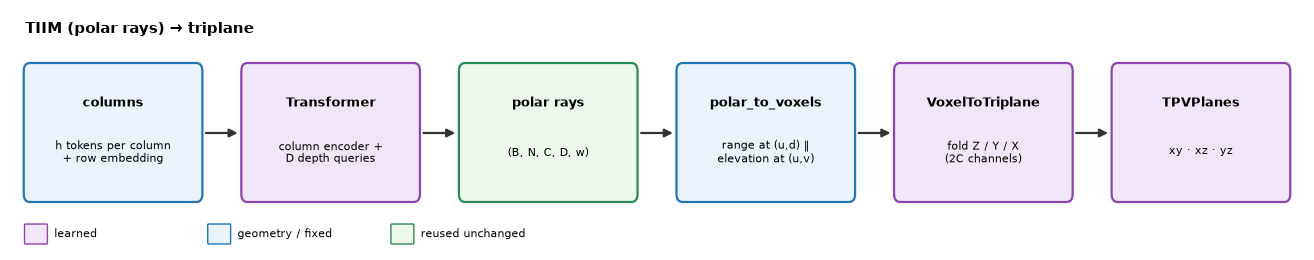

In [2]:
PipelineDiagram('TIIM (polar rays) → triplane').extend([
    ('columns', 'h tokens per column\n+ row embedding', 'geometry'),
    ('Transformer', 'column encoder +\nD depth queries', 'learned'),
    ('polar rays', '(B, N, C, D, w)', 'reused'),
    ('polar_to_voxels', 'range at (u,d) ‖\nelevation at (u,v)', 'geometry'),
    ('VoxelToTriplane', 'fold Z / Y / X\n(2C channels)', 'learned'),
    ('TPVPlanes', 'xy · xz · yz', 'learned'),
]).show()

## 2. The animation, one still per step

The GIF above is rendered by `lifting.triplane.animation` (Pillow only, exact geometry on a toy scene:
4 cameras at the origin, a car, a pedestrian and a pole). `StoryboardViewer` re-renders the **final frame of every
step** so the whole sequence can be read at once. Regenerate all GIFs with `python scripts/make_triplane_gifs.py`.

step 1: Inputs
step 2: Column transformer
step 3: Depth queries -> polar ray
step 4: Voxel reads range + elevation
step 5: Collapse Z, Y and X
step 6: Triplane output


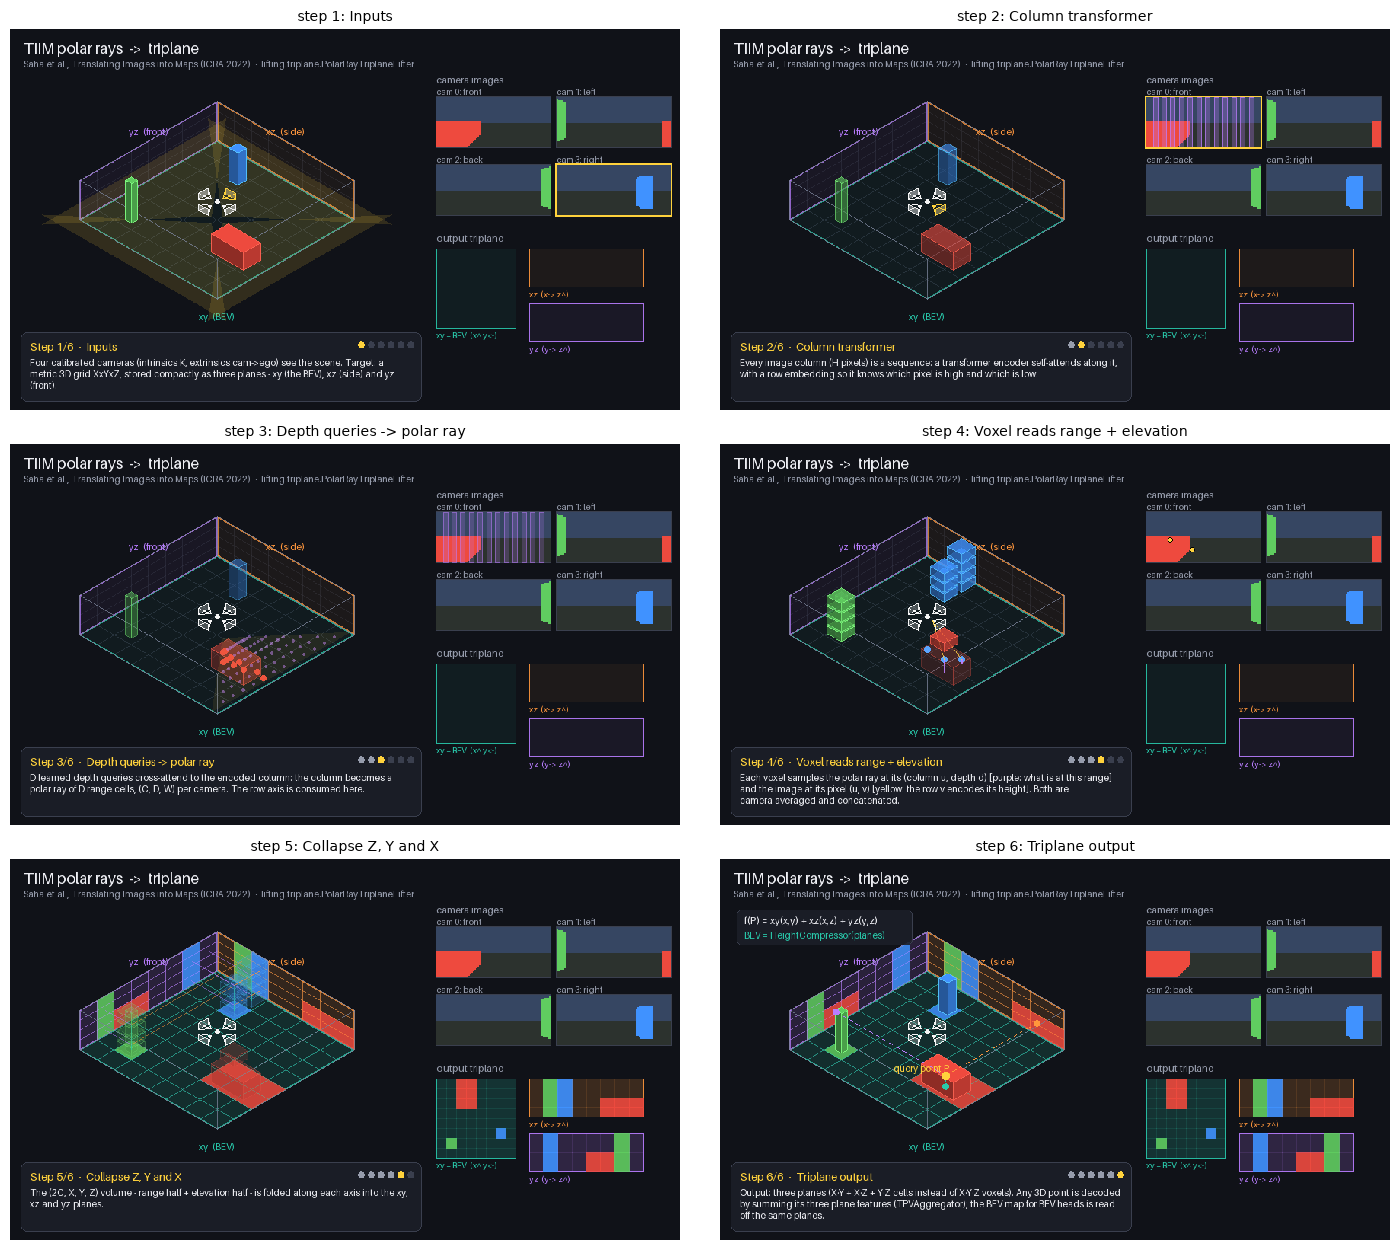

In [3]:
viewer = StoryboardViewer("tiim")
for i, title in enumerate(viewer.step_titles(), 1):
    print(f"step {i}: {title}")
viewer.contact_sheet()

## 3. The scene

Every triplane notebook uses the same `TriplaneScene`: a `32 m × 32 m × 4 m` region cut into `16 × 16 × 4`
cells, four `48 × 96` cameras whose yaw is **randomly rotated per scene** (so no network can memorise where
"front" is - it must read the calibration), and procedurally placed vehicles (red) and pedestrians (blue).
The ground truth is a 3D occupancy grid `(B, X, Y, Z)`; collapsing it along each axis gives the three
**label planes** each triplane is supervised against.

grid      : x (-16.0, 16.0) y (-16.0, 16.0) z (-1.0, 3.0) m, resolution (16, 16, 4)
voxel     : (2.0, 2.0, 1.0) m
cameras   : 4 x (48, 96) px
scenes    : 128 train / 32 test (batch 4)
TPV cells : xy 256 + xz 64 + yz 64 = 384  (voxels: 1024)


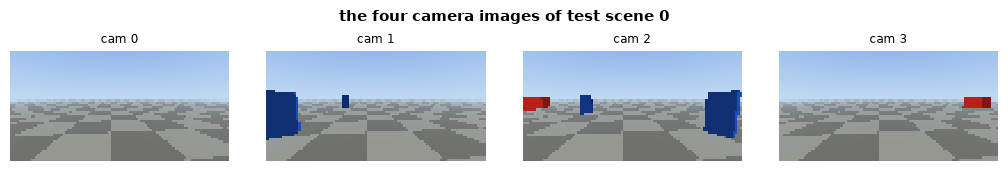

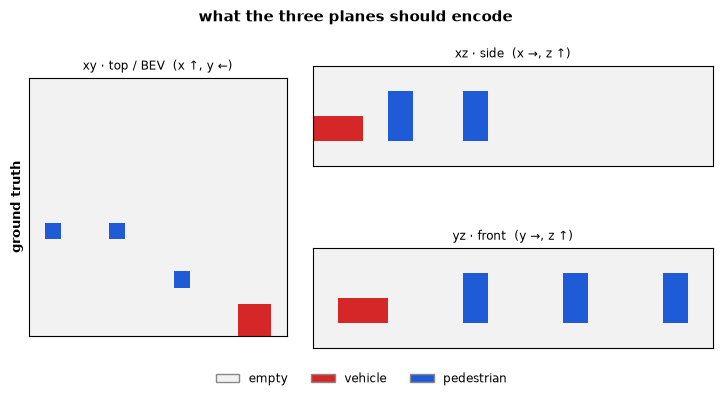

In [4]:
scene = TriplaneScene()
print(scene.describe())
batch = scene.sample
plotter.cameras(batch.images, title="the four camera images of test scene 0")
plotter.labels([("ground truth", scene.label_planes(batch.occupancy))], title="what the three planes should encode")

## 4. Build the triplane lifter

Two equivalent ways:

* `TRIPLANE_LIFTERS.build("tiim", grid=..., in_channels=..., out_channels=...)` - the raw registry;
* `build_triplane_lifter("tiim", grid, channels, image_size, num_cameras, encoder)` - also injects the
  context some lifters need (`feature_size`, `num_cameras`, `depth_bins`), exactly like `lifting.models.build_lifter`
  does for BEV lifters.

The image encoder turns `(B·N, 3, H, W)` images into a feature pyramid (strides 4 and 8 here); every lifter
consumes `(B, N, C, H_l, W_l)` per level.

In [5]:
C = 32
encoder = SimpleConvEncoder(out_channels=C, num_levels=2)
features = scene.encode(encoder, batch)
cameras = batch.cameras
print("feature pyramid:", [tuple(f.shape) for f in features])

lifter = build_triplane_lifter("tiim", scene.grid, C, scene.image_size, scene.num_cameras, encoder)
print(type(lifter).__name__, "| is a BaseLifter too:", isinstance(lifter, BaseLifter))
print(f"parameters: {sum(p.numel() for p in lifter.parameters()):,}")
for name, child in lifter.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"  .{name:<12s} {type(child).__name__:<28s} {n:>9,} params")

feature pyramid: [(4, 4, 32, 12, 24), (4, 4, 32, 6, 12)]
PolarRayTriplaneLifter | is a BaseLifter too: True
parameters: 728,160
  .bev_head     TriplaneBEVHead                 37,984 params
  .core         PolarRayLifter                  23,264 params
  .to_planes    VoxelToTriplane                666,912 params


## 5. Inside the lifter, step by step

### 5.1 Image columns → polar rays

image level: (4, 4, 32, 12, 24) -> polar rays: (4, 4, 32, 24, 24)
each of the 24 columns of each camera became 24 range cells


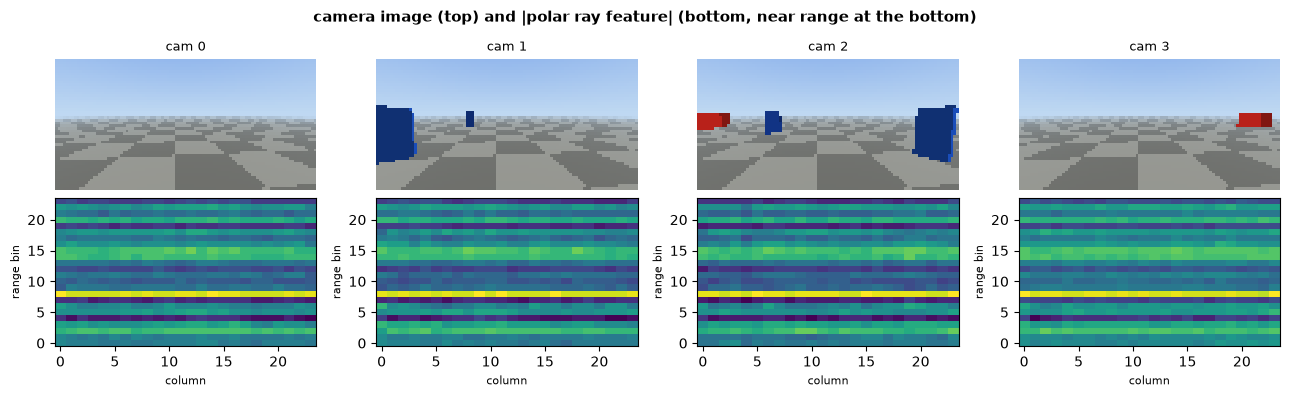

In [6]:
polar = lifter.image_to_polar(features)                 # (B, N, C, D, w)
print("image level:", tuple(features[lifter.level].shape), "-> polar rays:", tuple(polar.shape))
print(f"each of the {polar.shape[-1]} columns of each camera became {polar.shape[3]} range cells")
fig, axes = plt.subplots(2, scene.num_cameras, figsize=(13, 4), facecolor="white")
for n in range(scene.num_cameras):
    axes[0, n].imshow(batch.images[0, n].permute(1, 2, 0)); axes[0, n].set_title(f"cam {n}", fontsize=9)
    axes[1, n].imshow(polar[0, n].norm(dim=0).detach(), origin="lower", aspect="auto", cmap="viridis")
    axes[1, n].set_xlabel("column", fontsize=8); axes[1, n].set_ylabel("range bin", fontsize=8)
for ax in axes[0]: ax.axis("off")
plt.suptitle("camera image (top) and |polar ray feature| (bottom, near range at the bottom)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### 5.2 Polar rays → voxels: range **and** elevation

The first `C` channels come from the polar rays (range), the last `C` from the image rows (elevation).
A polar ray has no height axis, so the **range half barely changes along `Z`** while the elevation half does - that
is exactly why the elevation read is needed for the `xz` / `yz` planes. The cell below measures it.

uv (4, 4, 1024, 2) | fraction of voxels seen by >= 1 camera: 0.988


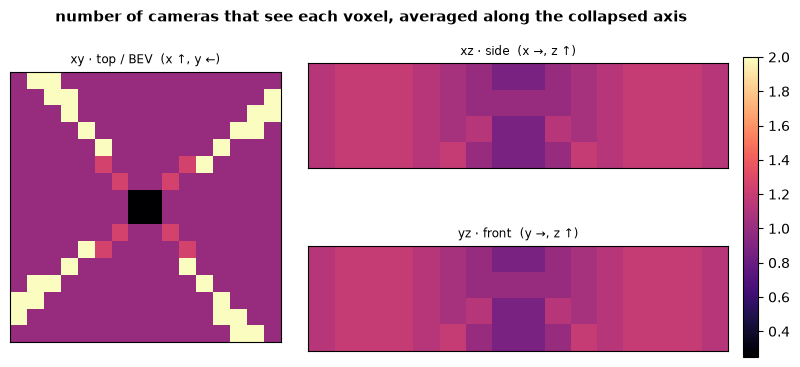

In [7]:
# How many cameras see every voxel centre? (the geometry every voxel-based lifter relies on)
pts = scene.grid.voxel_centers().view(1, -1, 3).expand(batch.images.shape[0], -1, -1)
uv, depth, valid = cameras.project(pts)                      # (B, N, X*Y*Z, 2), (B, N, P), (B, N, P)
seen = valid.sum(1)[0].view(*scene.grid.resolution).float() # cameras that see each voxel, scene 0
print("uv", tuple(uv.shape), "| fraction of voxels seen by >= 1 camera:", round((seen > 0).float().mean().item(), 3))
plotter.scalar_planes([seen.mean(2), seen.mean(1), seen.mean(0)],
                      "number of cameras that see each voxel, averaged along the collapsed axis", cmap="magma")

In [8]:
voxels = lifter.lift_voxels(features, cameras)         # (B, 2C, X, Y, Z)
c = voxels.shape[1] // 2
rng, elv = voxels[:, :c], voxels[:, c:]
def z_variation(v):  # how much a voxel feature changes along height, relative to its magnitude
    return (v.std(dim=4).mean() / v.abs().mean().clamp_min(1e-8)).item()
print("voxel volume:", tuple(voxels.shape), "= [range | elevation]")
print(f"relative variation along Z  - range half: {z_variation(rng):.3f}   elevation half: {z_variation(elv):.3f}")

voxel volume: (4, 64, 16, 16, 4) = [range | elevation]
relative variation along Z  - range half: 0.201   elevation half: 0.571


### Collapse the volume into three planes: `VoxelToTriplane`

A BEV lifter ends with a `HeightCompressor`: fold `Z` into the channels (`C·Z`) and convolve over `(X, Y)`.
`VoxelToTriplane` does that **three times**, each time moving a different axis to the end:

| plane | permute `(B, C, X, Y, Z)` → | folded axis | conv over |
|---|---|---|---|
| `xy` | `(B, C, X, Y, Z)` | `Z` | `(X, Y)` |
| `xz` | `(B, C, X, Z, Y)` | `Y` | `(X, Z)` |
| `yz` | `(B, C, Y, Z, X)` | `X` | `(Y, Z)` |

**Why fold rather than average?** Folding keeps *where along the collapsed axis* a feature was: the `xz` plane
can still tell a car on the left from one on the right. The next cell proves it on a toy volume.

In [9]:
from lifting.triplane import VoxelToTriplane
from lifting.geometry import GridSpec

tiny = GridSpec(resolution=(2, 3, 2))
to_planes = VoxelToTriplane(in_channels=1, grid=tiny, out_channels=4).eval()
a = torch.zeros(1, 1, 2, 3, 2); a[..., 0, 0, 1] = 1.0      # feature at y = 0 (left)
b = torch.zeros(1, 1, 2, 3, 2); b[..., 0, 2, 1] = 1.0      # same feature at y = 2 (right)
with torch.no_grad():
    pa, pb = to_planes(a), to_planes(b)
print("mean over Y identical?      ", torch.equal(a.mean(3), b.mean(3)), "  <- averaging would lose left vs right")
print("folded xz planes identical? ", torch.allclose(pa.xz, pb.xz), " <- VoxelToTriplane keeps it")
print("compressor weights (C_in·folded axis -> C_out):",
      {k: tuple(m.weight.shape) for k, m in to_planes.named_modules() if isinstance(m, torch.nn.Conv2d)})

mean over Y identical?       True   <- averaging would lose left vs right
folded xz planes identical?  False  <- VoxelToTriplane keeps it
compressor weights (C_in·folded axis -> C_out): {'compress_xy.conv.0.0': (4, 2, 3, 3), 'compress_xy.conv.1': (4, 4, 1, 1), 'compress_xz.conv.0.0': (4, 3, 3, 3), 'compress_xz.conv.1': (4, 4, 1, 1), 'compress_yz.conv.0.0': (4, 2, 3, 3), 'compress_yz.conv.1': (4, 4, 1, 1)}


In [10]:
voxels = lifter.lift_voxels(features, cameras)
planes = lifter.to_planes(voxels)
print("voxels", tuple(voxels.shape), "->", {k: tuple(getattr(planes, k).shape) for k in ("xy", "xz", "yz")})
print(f"memory: voxels {voxels[0].numel():,} floats per scene vs planes "
      f"{sum(getattr(planes, k)[0].numel() for k in ('xy', 'xz', 'yz')):,}")

voxels (4, 64, 16, 16, 4) -> {'xy': (4, 32, 16, 16), 'xz': (4, 32, 16, 4), 'yz': (4, 32, 16, 4)}
memory: voxels 65,536 floats per scene vs planes 12,288


## 6. The triplane contract, verified

Every triplane lifter promises the same five properties (Liskov: it is still a `BaseLifter`, so it drops into
`BEVSegmentationModel`, the trainer and the verifier unchanged). `TriplaneContractChecker` runs them on real tensors.

PASS  plane shapes            xy(4, 32, 16, 16) xz(4, 32, 16, 4) yz(4, 32, 16, 4)
PASS  BEV = bev_head(planes)  BEV (4, 32, 16, 16), max |diff| = 0.0e+00
PASS  f = xy + xz + yz        voxel (8,8,2) max |diff| = 0.0e+00
PASS  reuses BEV lifter       core = PolarRayLifter = LIFTERS['tiim']
PASS  gradients reach images  1/2 pyramid levels receive gradient


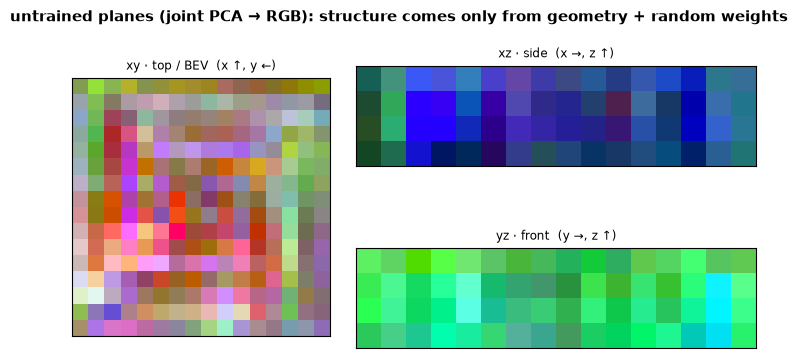

In [11]:
assert TriplaneContractChecker(lifter, features, cameras).run()
with torch.no_grad():
    planes = lifter.lift_planes(features, cameras)
plotter.features(planes, title="untrained planes (joint PCA → RGB): structure comes only from geometry + random weights")

## 7. Train end to end on 3D semantic occupancy

`build_triplane_model("tiim", ...)` = encoder → **this triplane lifter** → `TPVAggregator` (an MLP on
`f(x,y,z) = xy + xz + yz`), plus one auxiliary classifier per plane. `OccupancyTask(aux_weight=0.5)` adds a
cross-entropy on each plane against the collapsed labels of §3. 150 AdamW steps on 128 scenes, CPU only.

lifter          params    time   before    after  corrupted   verdict
tiim              865k    6.7s    0.004    0.386      0.031   uses geometry


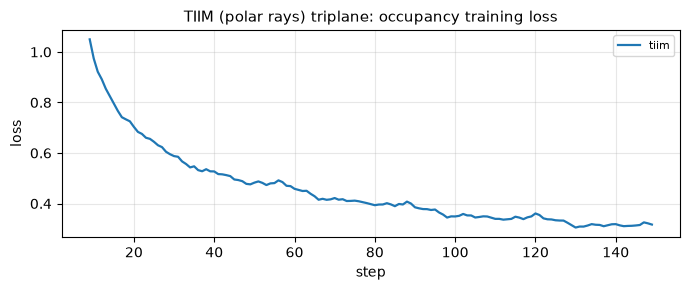

In [12]:
exp = OccupancyExperiment(scene, "tiim")
result = exp.run(steps=150)
print(ExperimentResult.header()); print(result.row())
OccupancyExperiment.plot_losses([result], title="TIIM (polar rays) triplane: occupancy training loss")

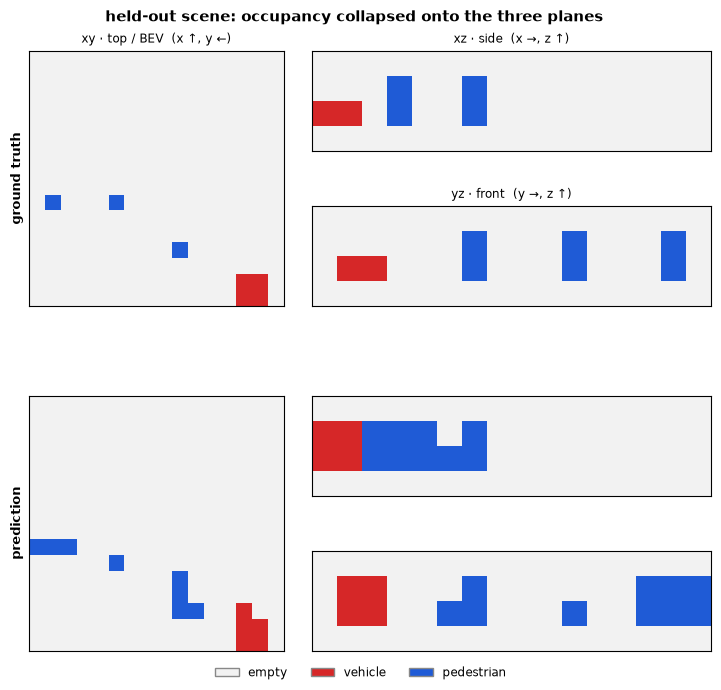

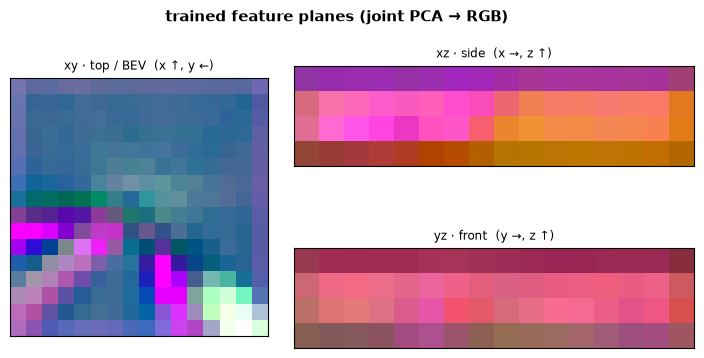

In [13]:
out = exp.predict()
pred = out["voxel_logits"].argmax(1)                       # (B, X, Y, Z) class ids
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("prediction", scene.label_planes(pred))],
               title="held-out scene: occupancy collapsed onto the three planes")
plotter.features(out["planes"], title="trained feature planes (joint PCA → RGB)")

## 8. Negative control: does it really use the cameras?

Same images, same weights - but every camera's extrinsic is rotated by 90° about the vertical axis. A lifter that reads
pixels **through** the calibration now puts every object in the wrong place and its mIoU collapses; a geometry-free
lifter would not notice. (This is the triplane version of the repo's `lifting-verify` check.)

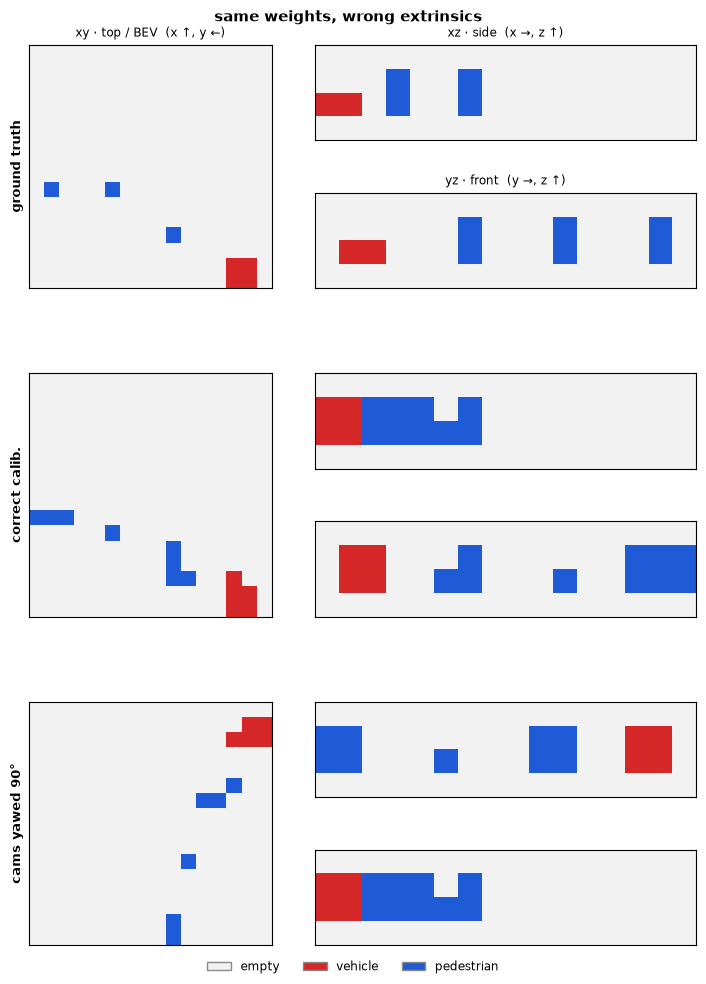

mIoU  correct calibration: 0.386   |   cameras yawed 90°: 0.031   ->  uses geometry ✅


In [14]:
corrupted = exp.predict(corrupted=True)["voxel_logits"].argmax(1)
plotter.labels([("ground truth", scene.label_planes(batch.occupancy)),
                ("correct calib.", scene.label_planes(pred)),
                ("cams yawed 90°", scene.label_planes(corrupted))],
               title="same weights, wrong extrinsics")
print(f"mIoU  correct calibration: {result.miou_after:.3f}   |   cameras yawed 90°: {result.miou_corrupted:.3f}"
      f"   ->  {'uses geometry ✅' if result.uses_geometry else 'does NOT use geometry'}")

## 9. Use it in your own code

```python
from lifting.triplane import TRIPLANE_LIFTERS, build_triplane_model, build_triplane_bev_model

# 1) just the lifter: features (B, N, C, H_l, W_l) per level + Cameras
lifter = TRIPLANE_LIFTERS.build("tiim", grid=grid, in_channels=64, out_channels=64)
planes = lifter.lift_planes(features, cameras)   # TPVPlanes(xy, xz, yz)
bev    = lifter(features, cameras)               # (B, 64, X, Y) - drop-in BEV lifter

# 2) 3D semantic occupancy + point queries
model = build_triplane_model("tiim", grid, num_classes=3, aux_heads=True)
out = model(images, cameras, points=lidar_xyz)   # planes, voxel_logits, point_logits, aux_logits

# 3) BEV segmentation read off the triplane (same API as lifting.build_bev_model)
bev_model = build_triplane_bev_model("tiim", grid, num_classes=3)
```

In [15]:
bev_model = build_triplane_bev_model("tiim", scene.grid, 3, scene.image_size, scene.num_cameras, channels=16)
with torch.no_grad():
    logits = bev_model(batch.images, batch.cameras)["logits"]
print("BEV segmentation logits read off the triplane:", tuple(logits.shape))

BEV segmentation logits read off the triplane: (4, 3, 16, 16)


## Recap


* TIIM translates each image column into a polar ray of range cells with a transformer (unchanged here).
* Polar rays lose height, so the triplane version adds an **elevation read** from the image rows: `2C` channels per voxel.
* The voxel volume is then collapsed like every other voxel-based technique.


**Cheat sheet**

| concept | file |
|---|---|
| column transformer + polar rays (unchanged) | `src/lifting/lifters/polar_ray_lifter.py` |
| range + elevation voxels | `src/lifting/triplane/polar_ray_triplane.py (`polar_to_voxels`)` |
| camera sampling ops | `src/lifting/ops/camera_sampling.py` |
| triplane contract | `src/lifting/triplane/base.py` |
| BEV read-off from planes | `src/lifting/triplane/triplane_bev_head.py` |
| occupancy model / factories | `src/lifting/triplane/triplane_occupancy_model.py`, `factory.py` |
| this animation | `src/lifting/triplane/animation/storyboards/tiim_storyboard.py` |

**Exercises**

1. Drop the elevation half (subclass and zero it). How much does the `xz` / `yz` auxiliary loss suffer?
2. Use 2 transformer layers (`num_layers=2`). Is it worth the extra time on this scene?
3. Plot the polar rays of the *trained* model (`exp.model.lifter.image_to_polar`).

Next: see `00_triplane_overview.ipynb` for all techniques side by side.